In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
plt.rcParams['font.family']= 'NanumGothic' 
plt.rcParams['axes.unicode_minus']=False

성남시 필터링

연령대별 업종 소비 응용집계 + 바차트 시각화

고령층(65세+) vs 기타 업종 소비 비교

고령층 업종별 1회 평균 구매금액 계산

고령층 이용건수 기준 업종별 순위 추출

유입지구분(CLN_REG_YN)에 따른 업종 소비 비교

성별 업종 소비 비교

In [ ]:
# CLN_REG_YN: Y(지역 거주자), N(외부 유입자)

성남시(SGG_NM == '성남시') 데이터 개수: 9
완


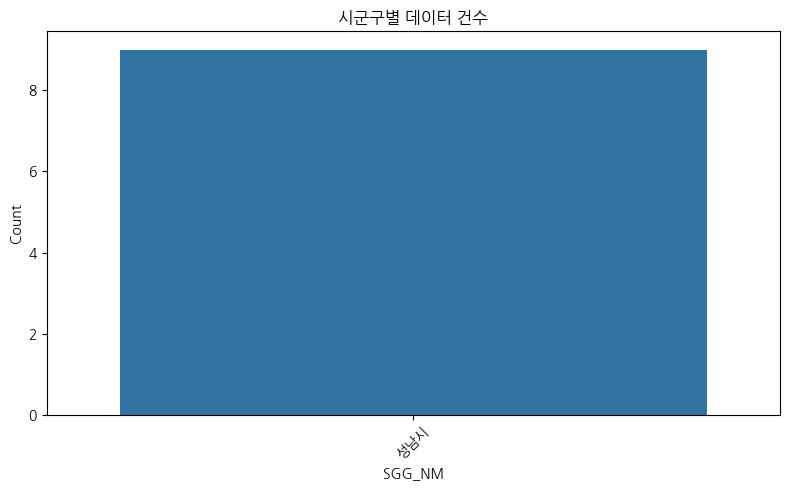

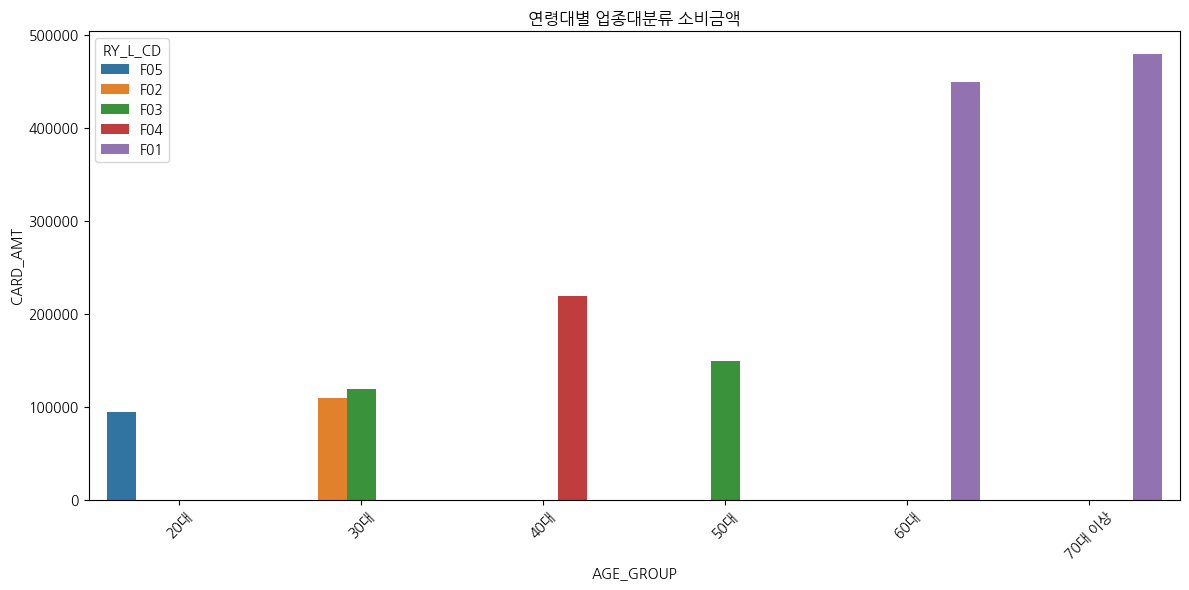

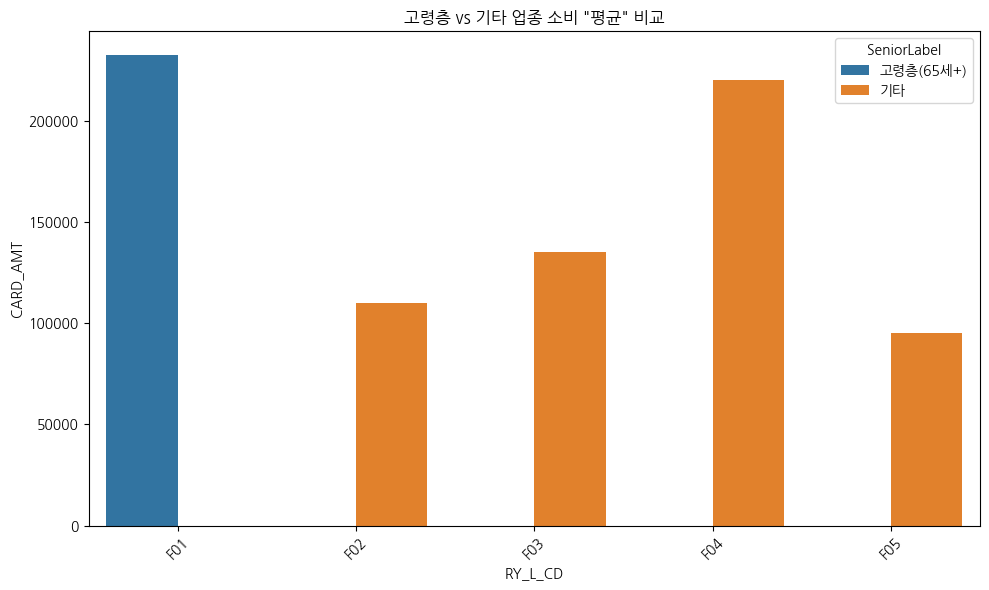

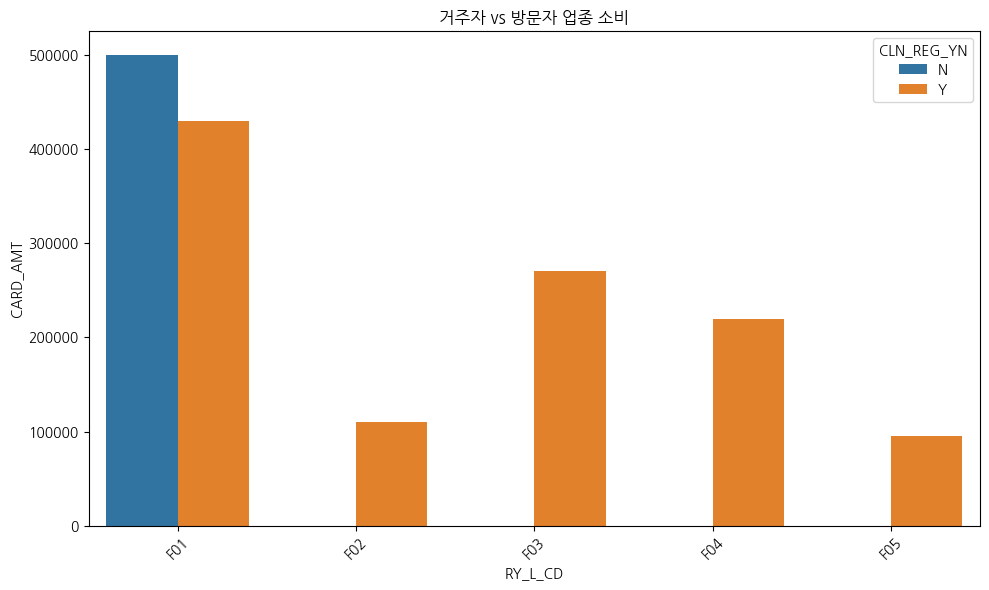

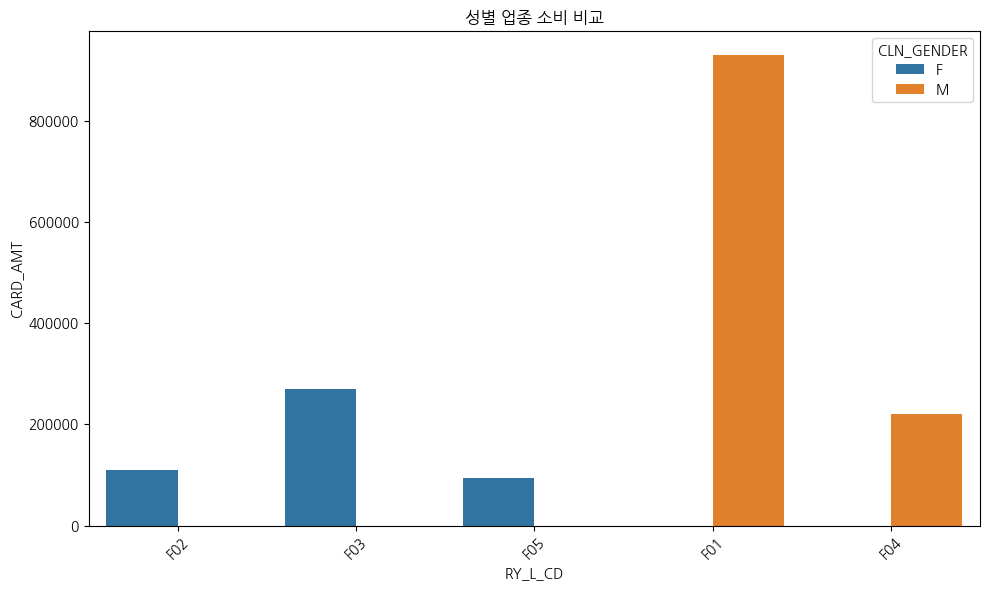

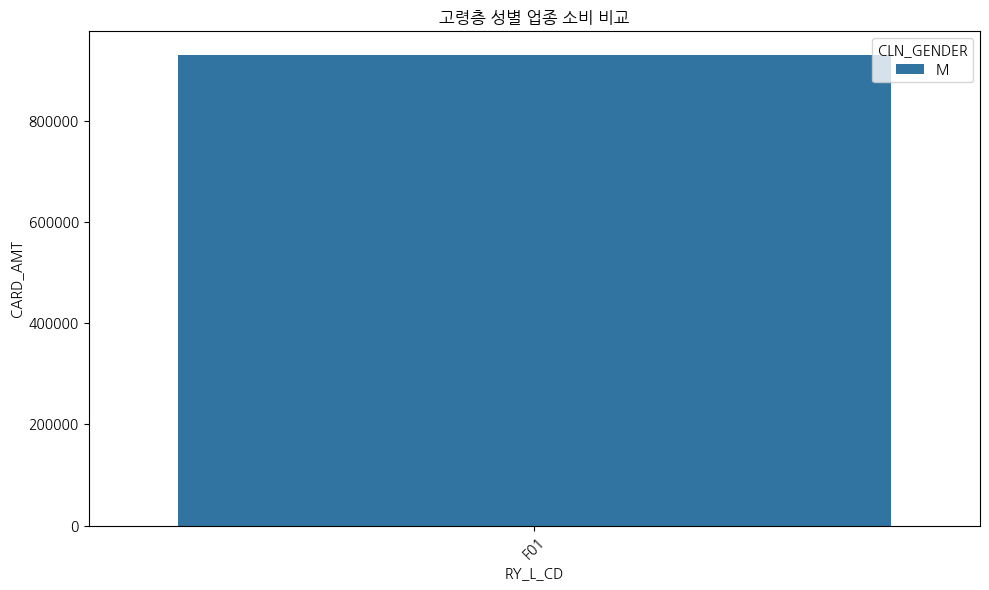

In [ ]:
# 필요한 라이브러리 불러오기
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 경고 제거
import warnings
warnings.filterwarnings("ignore")

# 파일 경로 및 이름 (데이터 수신 후 같은 경로에 둘 것)
file_path = "시군구별 일자별 금액건수_개인 (신한카드).txt"

# 데이터 불러오기 (탭 구분자)
try:
    df = pd.read_csv(file_path, sep="\t", encoding="utf-8")
except:
    df = pd.read_csv(file_path, sep="\t", encoding="cp949")

# 'CLN_GDS_NM'이 '성남'인 데이터만 필터링
df = df[df['CLN_GDS_NM'] == '성남'].copy()

# 이 중에서 SGG_NM이 '성남시'인 개수 출력 및 시군구별 시각화
print("성남시(SGG_NM == '성남시') 데이터 개수:", df[df['SGG_NM'] == '성남시'].shape[0])

sgg_counts = df['SGG_NM'].value_counts().reset_index()
sgg_counts.columns = ['SGG_NM', 'Count']
plt.figure(figsize=(8,5))
sns.barplot(data=sgg_counts, x='SGG_NM', y='Count')
plt.title('시군구별 데이터 건수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("시군구별_데이터건수.png")

# 날짜 파싱 및 월 추출
df['STD_YMD'] = pd.to_datetime(df['STD_YMD'], errors='coerce')
df['YEAR'] = df['STD_YMD'].dt.year
df['MONTH'] = df['STD_YMD'].dt.month

# 카드 금액과 건수 숫자형 변환
df['CARD_AMT'] = pd.to_numeric(df['CARD_AMT'], errors='coerce')
df['CARD_CNT'] = pd.to_numeric(df['CARD_CNT'], errors='coerce')

# 연령 숫자로 변환 후 연령대 그룹 추가
df['CLN_AGE'] = pd.to_numeric(df['CLN_AGE'], errors='coerce')
def get_age_group(age):
    if age >= 70: return '70대 이상'
    elif age >= 60: return '60대'
    elif age >= 50: return '50대'
    elif age >= 40: return '40대'
    elif age >= 30: return '30대'
    elif age >= 20: return '20대'
    else: return '10대 이하'
df['AGE_GROUP'] = df['CLN_AGE'].apply(get_age_group)

# 고령자 여부 추가
df['IS_SENIOR65'] = df['CLN_AGE'] >= 65

# 업종 대분류 기준 응용집계: 연령대별 업종 소비 금액
age_industry_amt = df.groupby(['AGE_GROUP', 'RY_L_CD'])['CARD_AMT'].sum().reset_index()
plt.figure(figsize=(12,6))
sns.barplot(data=age_industry_amt, x='AGE_GROUP', y='CARD_AMT', hue='RY_L_CD')
plt.title('연령대별 업종대분류 소비금액')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("연령대별_업종별_소비금액.png")

# 고령층(65세 이상) vs 비고령층 업종 소비 평균 비교
grouped = df.copy()
grouped['SeniorLabel'] = grouped['IS_SENIOR65'].map({True:'고령층(65세+)', False:'기타'})
senior_compare_mean = grouped.groupby(['SeniorLabel', 'RY_L_CD'])['CARD_AMT'].mean().reset_index()
plt.figure(figsize=(10,6))
sns.barplot(data=senior_compare_mean, x='RY_L_CD', y='CARD_AMT', hue='SeniorLabel')
plt.title('고령층 vs 기타 업종 소비 "평균" 비교')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("고령층_업종_평균비교.png")

# 고령층 업종별 1회 평균 구매금액
senior = df[df['IS_SENIOR65']].copy()
senior_avg = senior.groupby('RY_L_CD').agg({'CARD_AMT':'sum', 'CARD_CNT':'sum'})
senior_avg['AVG_PER_PURCHASE'] = senior_avg['CARD_AMT'] / senior_avg['CARD_CNT']
senior_avg = senior_avg.sort_values('AVG_PER_PURCHASE', ascending=False)
senior_avg.to_csv("고령층_1회평균구매금액.csv")

# 고령층 건수 기준 상위/하위 업종
senior_cnt = senior.groupby('RY_L_CD')['CARD_CNT'].sum().sort_values(ascending=False)
senior_cnt.to_csv("고령층_업종별_이용건수순위.csv")

# 유입지구분(Y/N)에 따른 업종 소비 비교
if 'CLN_REG_YN' in df.columns:
    inflow_group = df.groupby(['CLN_REG_YN', 'RY_L_CD'])['CARD_AMT'].sum().reset_index()
    plt.figure(figsize=(10,6))
    sns.barplot(data=inflow_group, x='RY_L_CD', y='CARD_AMT', hue='CLN_REG_YN')
    plt.title('거주자 vs 방문자 업종 소비')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig("유입지구분별_업종소비.png")

# 성별 업종 선호 분석 (전체)
gender_group = df.groupby(['CLN_GENDER', 'RY_L_CD'])['CARD_AMT'].sum().reset_index()
plt.figure(figsize=(10,6))
sns.barplot(data=gender_group, x='RY_L_CD', y='CARD_AMT', hue='CLN_GENDER')
plt.title('성별 업종 소비 비교')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("성별_업종소비.png")

# 고령층 성별 업종 선호 분석
senior_gender_group = senior.groupby(['CLN_GENDER', 'RY_L_CD'])['CARD_AMT'].sum().reset_index()
plt.figure(figsize=(10,6))
sns.barplot(data=senior_gender_group, x='RY_L_CD', y='CARD_AMT', hue='CLN_GENDER')
plt.title('고령층 성별 업종 소비 비교')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("고령층_성별_업종소비.png")

print("완")


In [ ]:
## 추가적 분석
# 1. 월별 시계열 분석
# 연령대별 월별 카드 사용 금액/건수 트렌드
# 고령층의 월별 업종별 소비 변화
# 특정 업종에서 고령층 소비가 증가/감소하는 추세 있는지

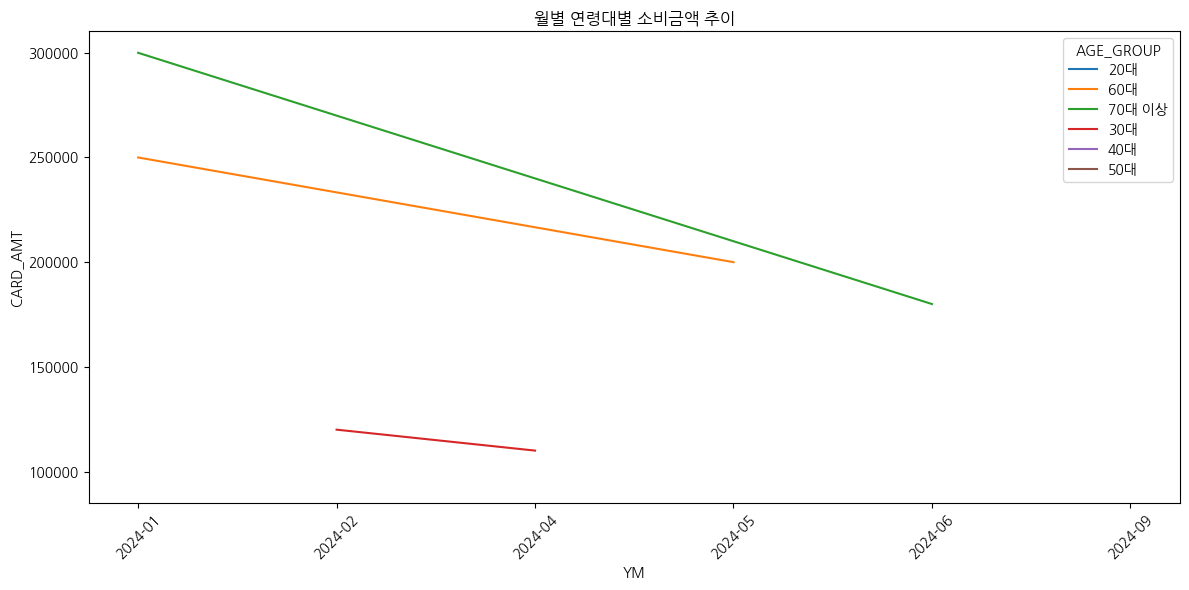

In [ ]:
# 월별 연령대별 소비 추이
monthly_trend = df.groupby(['YEAR', 'MONTH', 'AGE_GROUP'])['CARD_AMT'].sum().reset_index()
monthly_trend['YM'] = monthly_trend['YEAR'].astype(str) + '-' + monthly_trend['MONTH'].astype(str).str.zfill(2)

plt.figure(figsize=(12,6))
sns.lineplot(data=monthly_trend, x='YM', y='CARD_AMT', hue='AGE_GROUP')
plt.title('월별 연령대별 소비금액 추이')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("월별_연령대별_소비추이.png")


In [ ]:
업종 집중도 분석 (상대 소비 집중도)
목적: 연령대 또는 고령층이 특정 업종에 얼마나 집중하고 있는지 (비중 기준)

총 소비금액 대비 업종별 소비 비율 (%): 연령대별 / 고령층 vs 비고령층

Top-N 업종 비중이 전체 소비의 몇 %인지

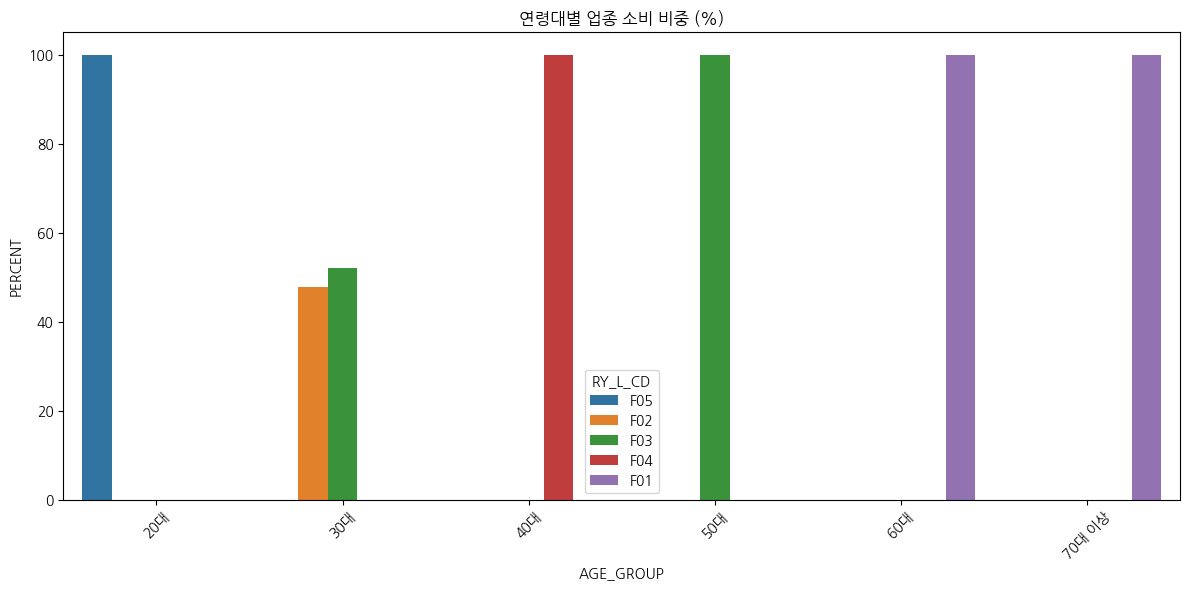

In [ ]:
# 연령대별 업종 소비 비중 (%)
group = df.groupby(['AGE_GROUP', 'RY_L_CD'])['CARD_AMT'].sum().reset_index()
group['TOTAL'] = group.groupby('AGE_GROUP')['CARD_AMT'].transform('sum')
group['PERCENT'] = 100 * group['CARD_AMT'] / group['TOTAL']

plt.figure(figsize=(12,6))
sns.barplot(data=group, x='AGE_GROUP', y='PERCENT', hue='RY_L_CD')
plt.title('연령대별 업종 소비 비중 (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("연령대별_업종비중.png")


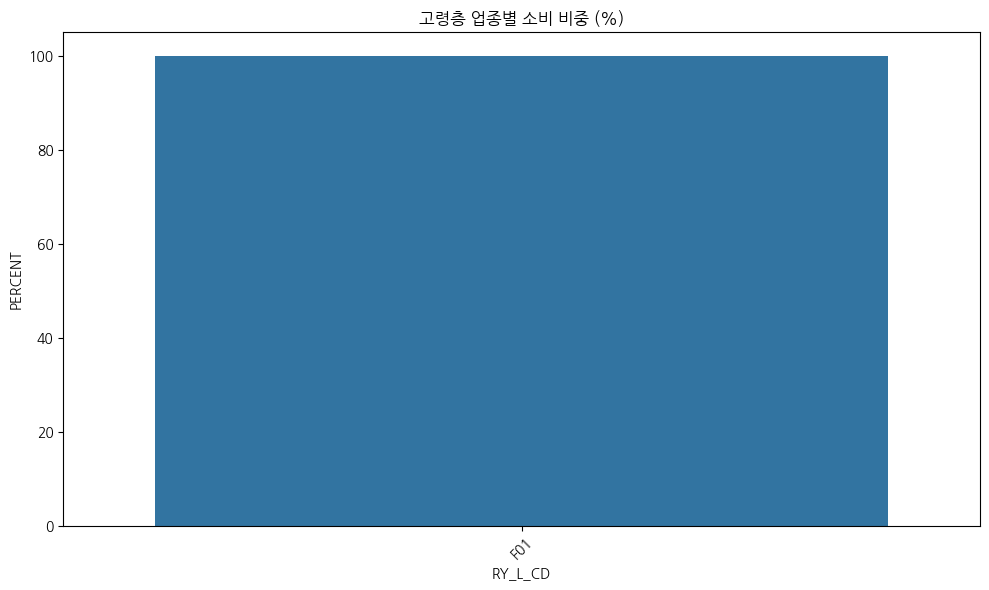

In [ ]:
## 고령화만 보자면. 
# 고령층(65세 이상)만 필터링
senior_df = df[df['IS_SENIOR65']]

# 고령층 업종 소비 비중 계산
group = senior_df.groupby(['RY_L_CD'])['CARD_AMT'].sum().reset_index()
total = group['CARD_AMT'].sum()
group['PERCENT'] = 100 * group['CARD_AMT'] / total

# 시각화
plt.figure(figsize=(10,6))
sns.barplot(data=group, x='RY_L_CD', y='PERCENT')
plt.title('고령층 업종별 소비 비중 (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("고령층_업종소비비중.png")


In [ ]:
# 계절성: 특정 달에 소비가 급증하는지

# 추세: 소비 규모가 점점 늘어나는지/줄어드는지

# 건수 vs 금액 차이: 활동성은 높지만 소액인지, 적게 쓰고 고액인지를 판단할 거

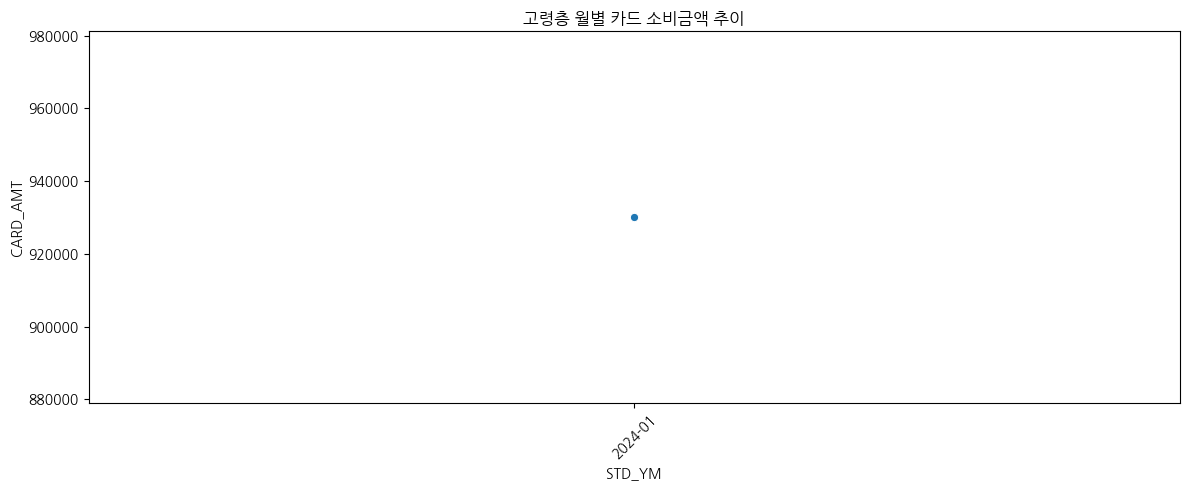

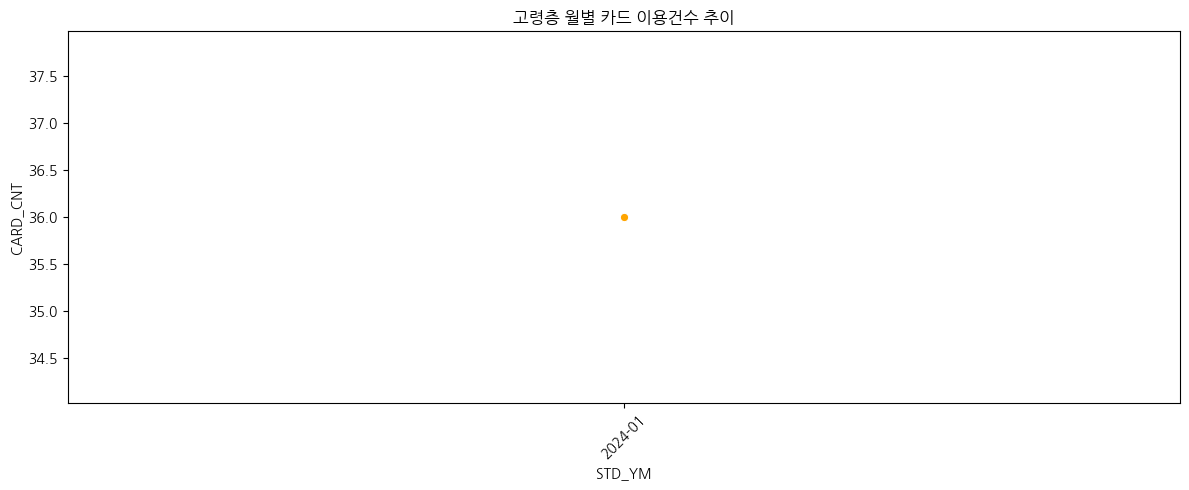

In [ ]:
# 1. 고령층만 필터링
senior_df = df[df['IS_SENIOR65']].copy()

# 2. STD_YM 컬럼이 문자열이면 정리 (예: '202401' → '2024-01')
senior_df['STD_YM'] = senior_df['STD_YM'].astype(str)
senior_df['STD_YM'] = senior_df['STD_YM'].str[:4] + '-' + senior_df['STD_YM'].str[4:]

# 3. 월별 소비금액 및 건수 집계
senior_monthly = senior_df.groupby('STD_YM')[['CARD_AMT', 'CARD_CNT']].sum().reset_index()

# 4. 시각화 - 소비금액 추이
plt.figure(figsize=(12,5))
sns.lineplot(data=senior_monthly, x='STD_YM', y='CARD_AMT', marker='o')
plt.title('고령층 월별 카드 소비금액 추이')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("고령층_월별소비금액추이.png")

# 5. 시각화 - 이용건수 추이
plt.figure(figsize=(12,5))
sns.lineplot(data=senior_monthly, x='STD_YM', y='CARD_CNT', marker='o', color='orange')
plt.title('고령층 월별 카드 이용건수 추이')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("고령층_월별이용건수추이.png")


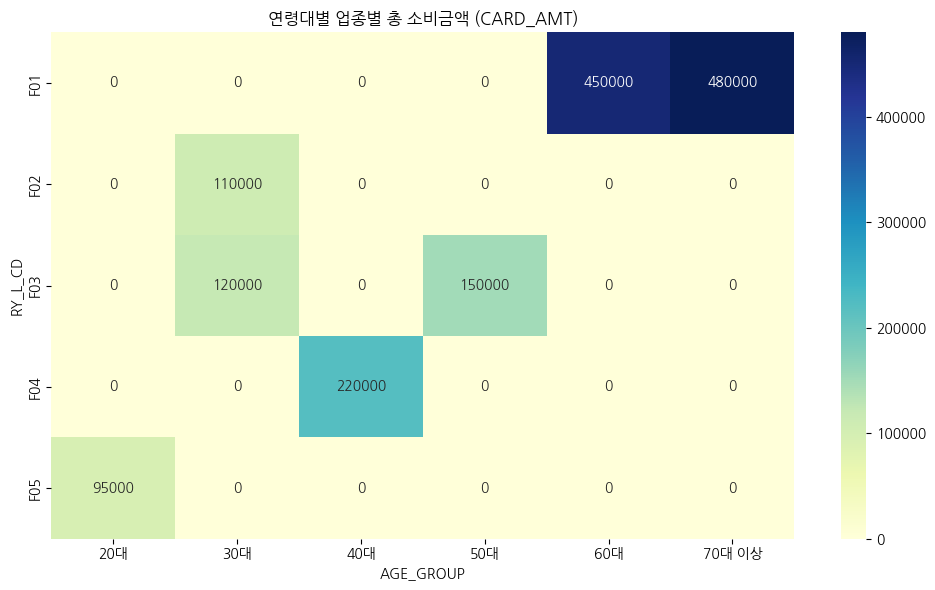

In [ ]:
# 연령대별 업종 소비금액 집계
pivot_amt = df.pivot_table(index='RY_L_CD', columns='AGE_GROUP', values='CARD_AMT', aggfunc='sum', fill_value=0)

# 시각화 (총 소비금액 기준)
plt.figure(figsize=(10,6))
sns.heatmap(pivot_amt, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('연령대별 업종별 총 소비금액 (CARD_AMT)')
plt.tight_layout()
plt.savefig('히트맵_연령대별_업종별_소비금액.png')

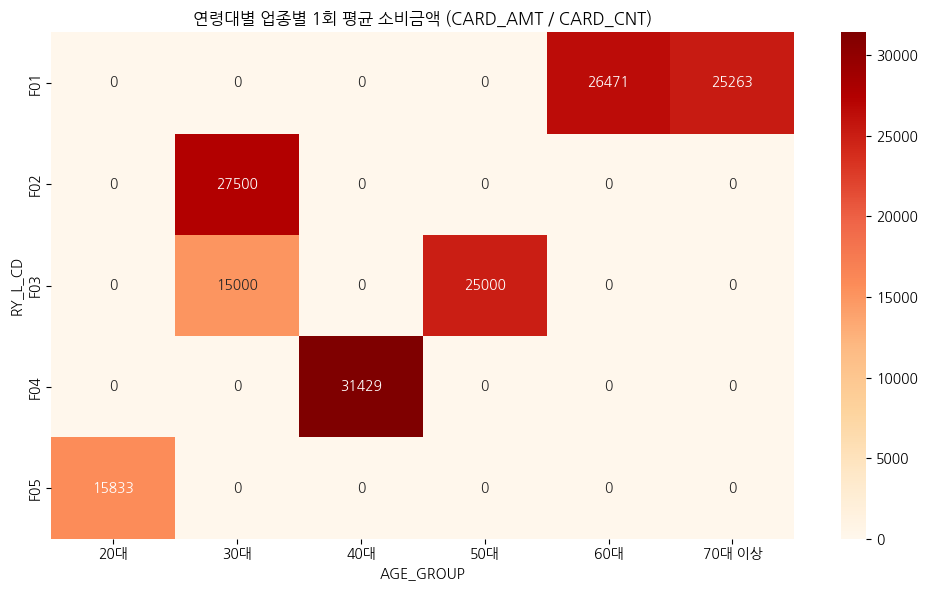

In [ ]:
# 연령대-업종별 평균 소비금액 (총액 ÷ 건수)
pivot_avg = df.pivot_table(index='RY_L_CD', columns='AGE_GROUP',
                           values=['CARD_AMT', 'CARD_CNT'], aggfunc='sum', fill_value=0)

# 평균값 계산 (주의: 0으로 나누는 경우 제외 처리)
avg_amt = pivot_avg['CARD_AMT'] / pivot_avg['CARD_CNT']
avg_amt = avg_amt.fillna(0)

# 시각화 (1회 평균 소비금액 기준)
plt.figure(figsize=(10,6))
sns.heatmap(avg_amt, annot=True, fmt='.0f', cmap='OrRd')
plt.title('연령대별 업종별 1회 평균 소비금액 (CARD_AMT / CARD_CNT)')
plt.tight_layout()
plt.savefig('히트맵_연령대별_업종별_1회평균소비.png')


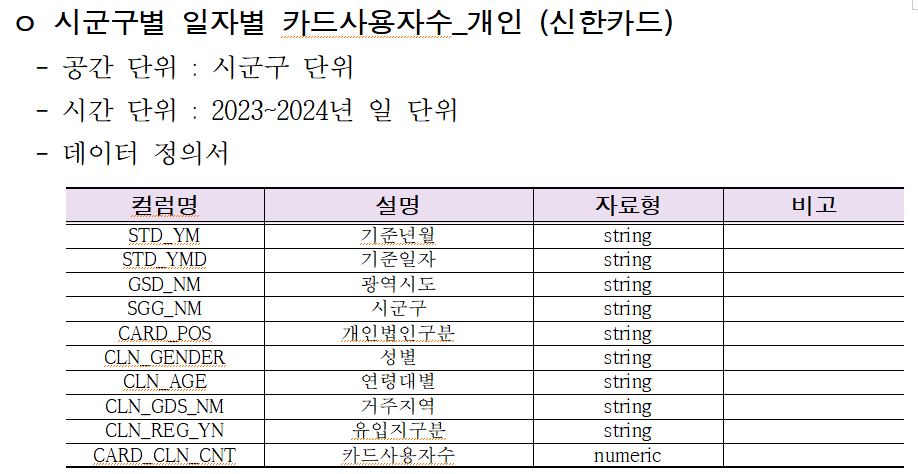

고령층(65세 이상) 사용자 비율: 16.31%
완


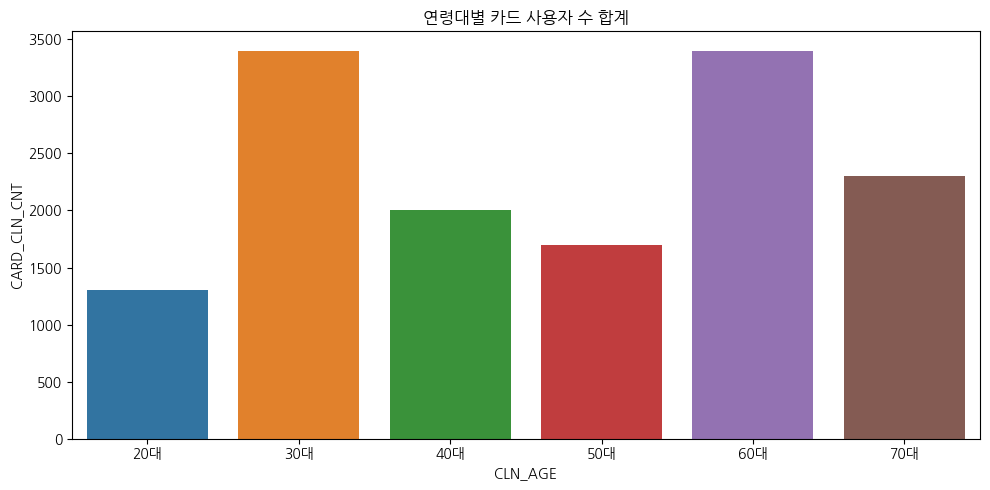

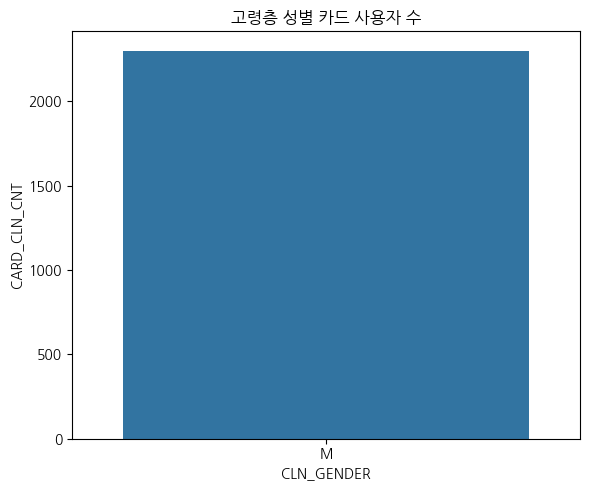

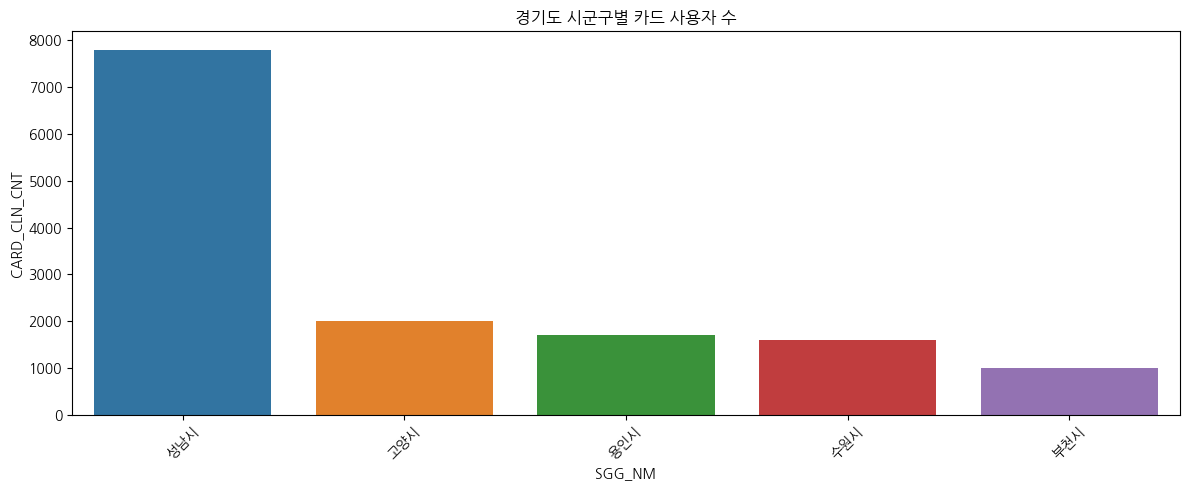

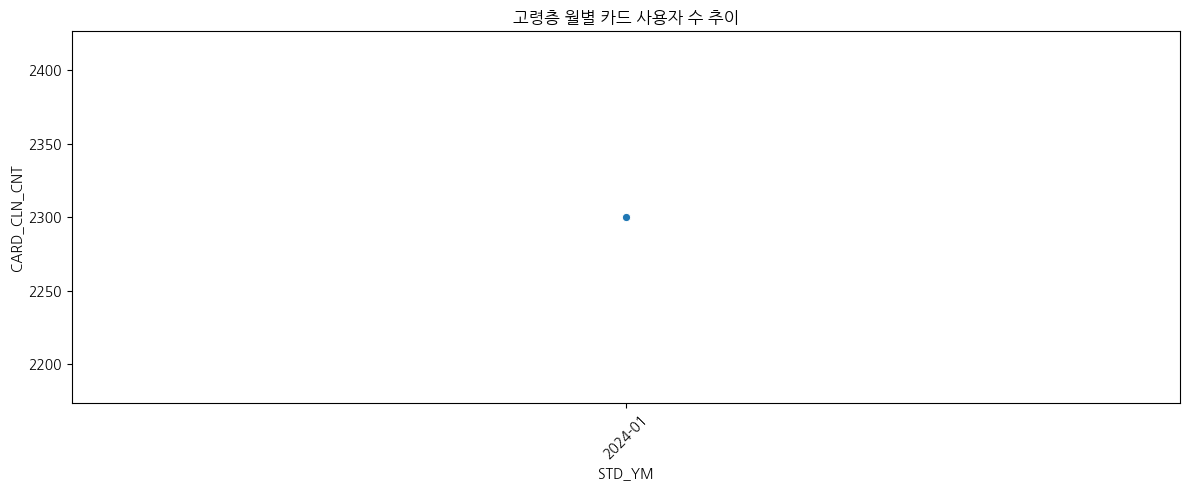

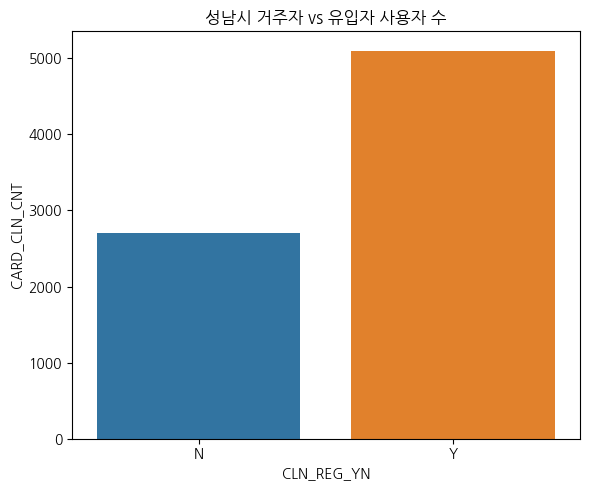

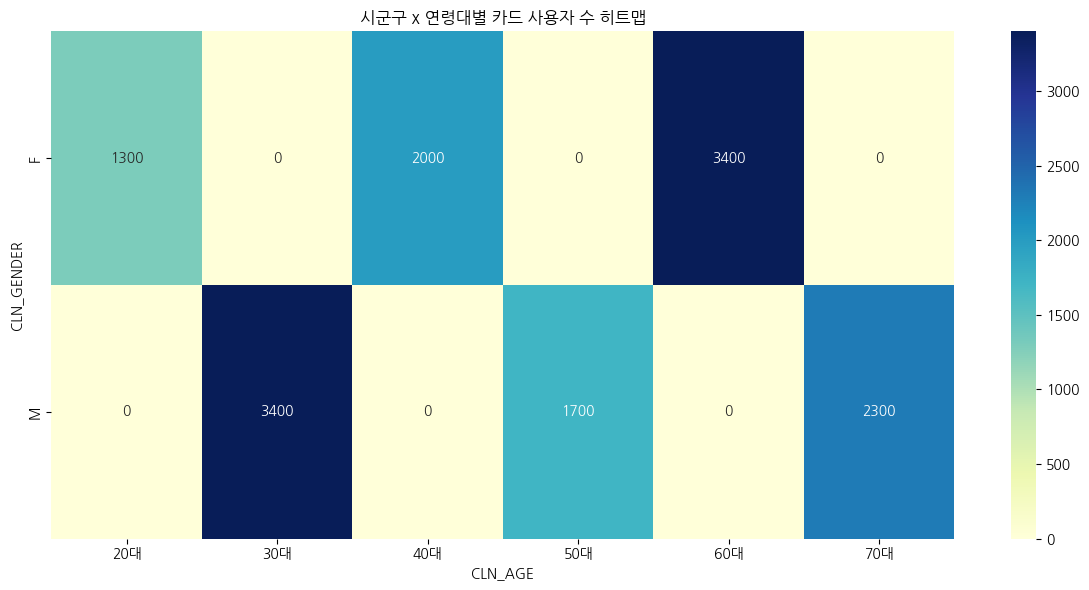

In [ ]:
# 데이터 불러오기
file_path = "시군구별 일자별 카드사용자수_개인 (신한카드).txt"
try:
    df = pd.read_csv(file_path, sep="\t", encoding="utf-8")
except:
    df = pd.read_csv(file_path, sep="\t", encoding="cp949")

# CARD_CLN_CNT 숫자형 변환
df['CARD_CLN_CNT'] = pd.to_numeric(df['CARD_CLN_CNT'], errors='coerce')

# 연령 숫자 추출 (예: '70대' → 70)
df['AGE_NUM'] = df['CLN_AGE'].str.extract(r'(\d+)').astype(float)

# 고령층 여부 컬럼 추가
df['IS_SENIOR65'] = df['AGE_NUM'] >= 65

# STD_YM 정리 (202401 → 2024-01)
df['STD_YM'] = df['STD_YM'].astype(str)
df['STD_YM'] = df['STD_YM'].str[:4] + '-' + df['STD_YM'].str[4:]

### 1. 연령대별 카드 사용자 수 분석
age_sum = df.groupby('CLN_AGE')['CARD_CLN_CNT'].sum().reset_index()
plt.figure(figsize=(10,5))
sns.barplot(data=age_sum, x='CLN_AGE', y='CARD_CLN_CNT')
plt.title('연령대별 카드 사용자 수 합계')
plt.tight_layout()
plt.savefig('연령대별_카드사용자수.png')

###2. 고령층 사용자 비율 분석 (전체 사용자 중 고령층 비중)
total_user = df['CARD_CLN_CNT'].sum()
senior_user = df[df['IS_SENIOR65']]['CARD_CLN_CNT'].sum()   # 65세 이상 사용자 수 
senior_ratio = round(100 * senior_user / total_user, 2)
print(f"고령층(65세 이상) 사용자 비율: {senior_ratio}%")

### 3. 고령층 성별 비교
gender_senior = df[df['IS_SENIOR65']].groupby('CLN_GENDER')['CARD_CLN_CNT'].sum().reset_index()
plt.figure(figsize=(6,5))
sns.barplot(data=gender_senior, x='CLN_GENDER', y='CARD_CLN_CNT')
plt.title('고령층 성별 카드 사용자 수')
plt.tight_layout()
plt.savefig('고령층_성별사용자수.png')

## 4. 경기도 내 성남시 vs 다른 시군구 비교
gg_df = df[df['GSD_NM'] == '경기도']
sgg_users = gg_df.groupby('SGG_NM')['CARD_CLN_CNT'].sum().reset_index().sort_values(by='CARD_CLN_CNT', ascending=False)
plt.figure(figsize=(12,5))
sns.barplot(data=sgg_users, x='SGG_NM', y='CARD_CLN_CNT')
plt.title('경기도 시군구별 카드 사용자 수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('경기도_시군구별_사용자수.png')

### 5. 고령층 월별 사용자 수 시계열
senior_monthly = df[df['IS_SENIOR65']].groupby('STD_YM')['CARD_CLN_CNT'].sum().reset_index()
plt.figure(figsize=(12,5))
sns.lineplot(data=senior_monthly, x='STD_YM', y='CARD_CLN_CNT', marker='o')
plt.title('고령층 월별 카드 사용자 수 추이')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('고령층_월별사용자수추이.png')

### 6. 성남시 거주자 vs 유입자 사용자 수 비교   ## 만약에 이를 비교했을 때 유입사용자가 예상보다 많으면 어떡하죠
sn = df[df['SGG_NM'] == '성남시']
if 'CLN_REG_YN' in sn.columns:
    inflow = sn.groupby('CLN_REG_YN')['CARD_CLN_CNT'].sum().reset_index()
    plt.figure(figsize=(6,5))
    sns.barplot(data=inflow, x='CLN_REG_YN', y='CARD_CLN_CNT')
    plt.title('성남시 거주자 vs 유입자 사용자 수')
    plt.tight_layout()
    plt.savefig('성남시_유입구분_사용자수.png')

### 7. 연령대별 셩별 카사수
heatmap_data = df.pivot_table(index='CLN_GENDER', columns='CLN_AGE', values='CARD_CLN_CNT', aggfunc='sum', fill_value=0)
plt.figure(figsize=(12,6))
sns.heatmap(heatmap_data, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('시군구 x 연령대별 카드 사용자 수 히트맵')
plt.tight_layout()
plt.savefig('시군구_연령대_히트맵.png')



print("완")


다른 데이터와 결합하면?
CARD_AMT (금액) 데이터와 결합 → 1인당 평균 소비금액 분석

CARD_CNT (건수) 데이터와 결합 → 1인당 평균 사용횟수 분석

→ 금액 / 사용자 수, 건수 / 사용자 수 등의 인당 지표

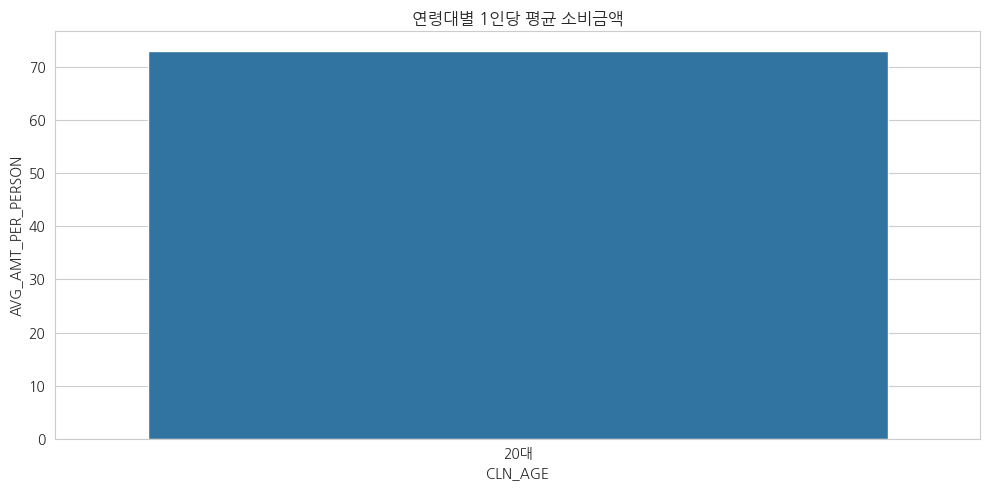

In [ ]:
# 1. 두 파일 불러오기
df_amt = pd.read_csv("시군구별 일자별 금액건수_개인 (신한카드).txt", sep="\t", encoding="utf-8")
df_user = pd.read_csv("시군구별 일자별 카드사용자수_개인 (신한카드).txt", sep="\t", encoding="utf-8")

# 2. 병합 기준 컬럼(날짜, 지역, 연령대, 성별, 거주지역)
cols = ['STD_YMD', 'SGG_NM', 'CLN_AGE', 'CLN_GENDER', 'CLN_GDS_NM']
#         날짜       지역      연령대      성별          거주지역   
# 3. 모든 병합 기준 컬럼을 문자열로 변환
for col in cols:
    df_amt[col] = df_amt[col].astype(str)
    df_user[col] = df_user[col].astype(str)

# 4. 필요한 컬럼만 추출
#df_amt: 소비금액, 건수
#df_user: 사용자수
df_amt = df_amt[cols + ['CARD_AMT', 'CARD_CNT']]
df_user = df_user[cols + ['CARD_CLN_CNT']]

# 5. 병합, 값이 일치하는 경우만 남김
df_merged = pd.merge(df_amt, df_user, on=cols, how='inner')

# 6. 인당 지표 계산
df_merged['AVG_AMT_PER_PERSON'] = df_merged['CARD_AMT'] / df_merged['CARD_CLN_CNT']
df_merged['AVG_CNT_PER_PERSON'] = df_merged['CARD_CNT'] / df_merged['CARD_CLN_CNT']
df_merged['AVG_AMT_PER_USE'] = df_merged['CARD_AMT'] / df_merged['CARD_CNT']

# 7. 예: 연령대별 평균 정리
grouped = df_merged.groupby('CLN_AGE')[['AVG_AMT_PER_PERSON', 'AVG_CNT_PER_PERSON', 'AVG_AMT_PER_USE']].mean().reset_index()

# 8. 시각화
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.barplot(data=grouped, x='CLN_AGE', y='AVG_AMT_PER_PERSON')
plt.title('연령대별 1인당 평균 소비금액')
plt.tight_layout()
plt.savefig('연령대별_1인당_소비금액.png')


In [ ]:
cols = ['STD_YMD', 'SGG_NM', 'CLN_AGE', 'CLN_GENDER', 'CLN_GDS_NM']

print("df_amt 샘플:")
print(df_amt[cols].drop_duplicates().head())

print("\ndf_user 샘플:")
print(df_user[cols].drop_duplicates().head())


In [ ]:
print(cols)

['STD_YMD', 'SGG_NM', 'CLN_AGE', 'CLN_GENDER', 'CLN_GDS_NM']


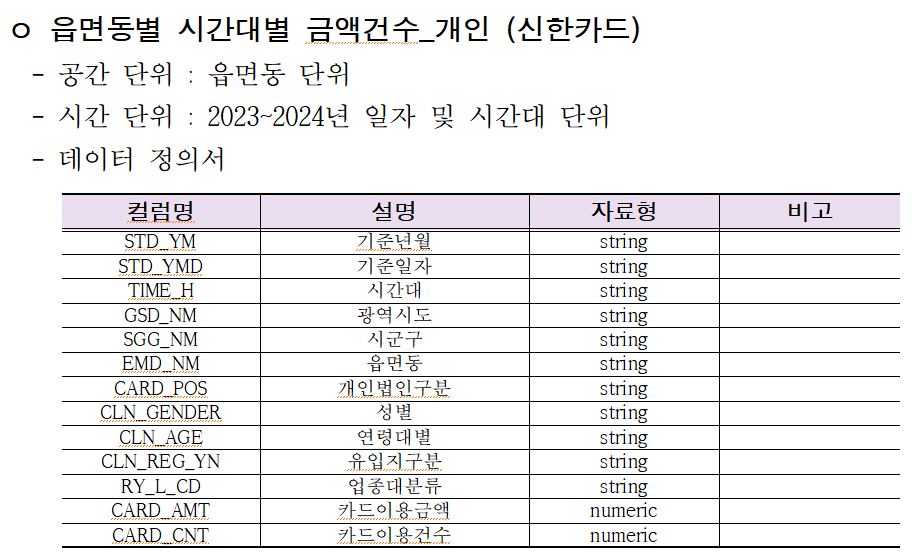

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

# 데이터 불러오기
df = pd.read_csv("읍면동별 시간대별 금액건수_개인.txt", sep="\t", encoding="utf-8")

# 전처리
df = df[df['SGG_NM'] == '성남시'].copy()  # 성남시만 필터링
df['CARD_AMT'] = pd.to_numeric(df['CARD_AMT'], errors='coerce')
df['CARD_CNT'] = pd.to_numeric(df['CARD_CNT'], errors='coerce')
df['AGE_NUM'] = df['CLN_AGE'].str.extract(r'(\\d+)').astype(float)
df['IS_SENIOR65'] = df['AGE_NUM'] >= 65


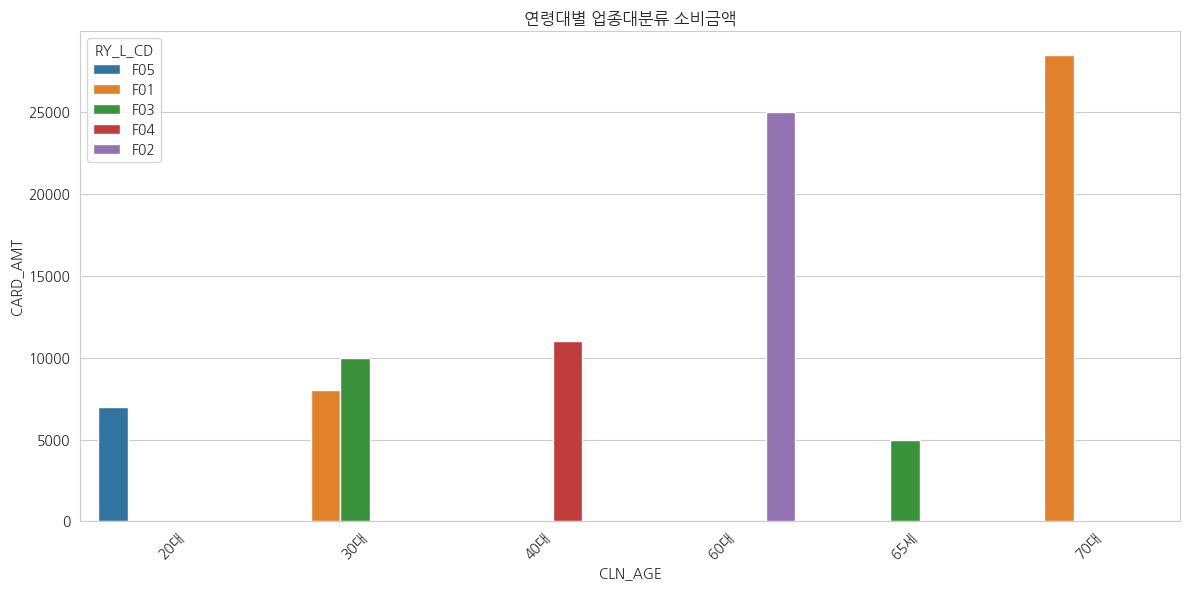

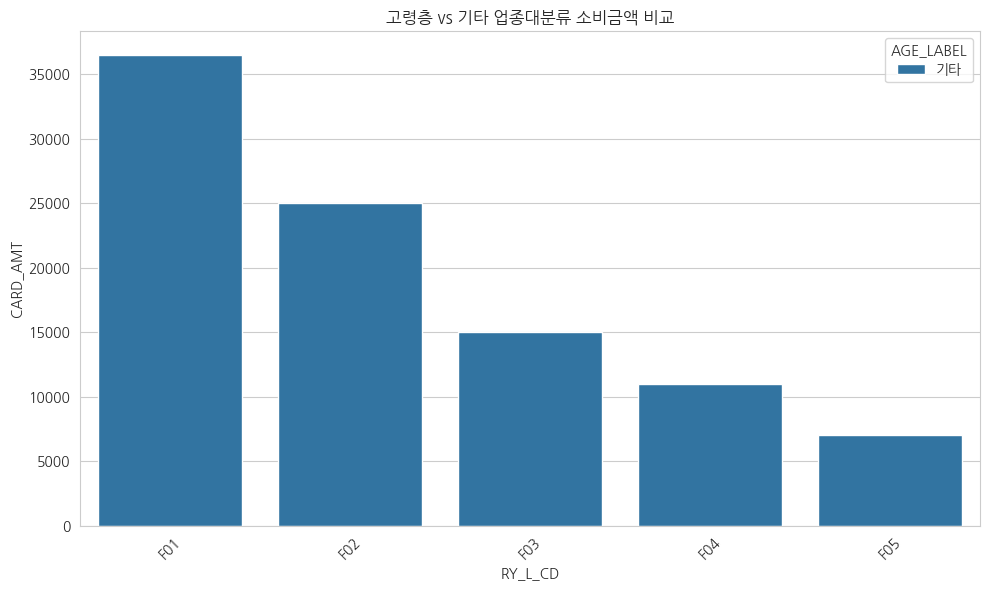

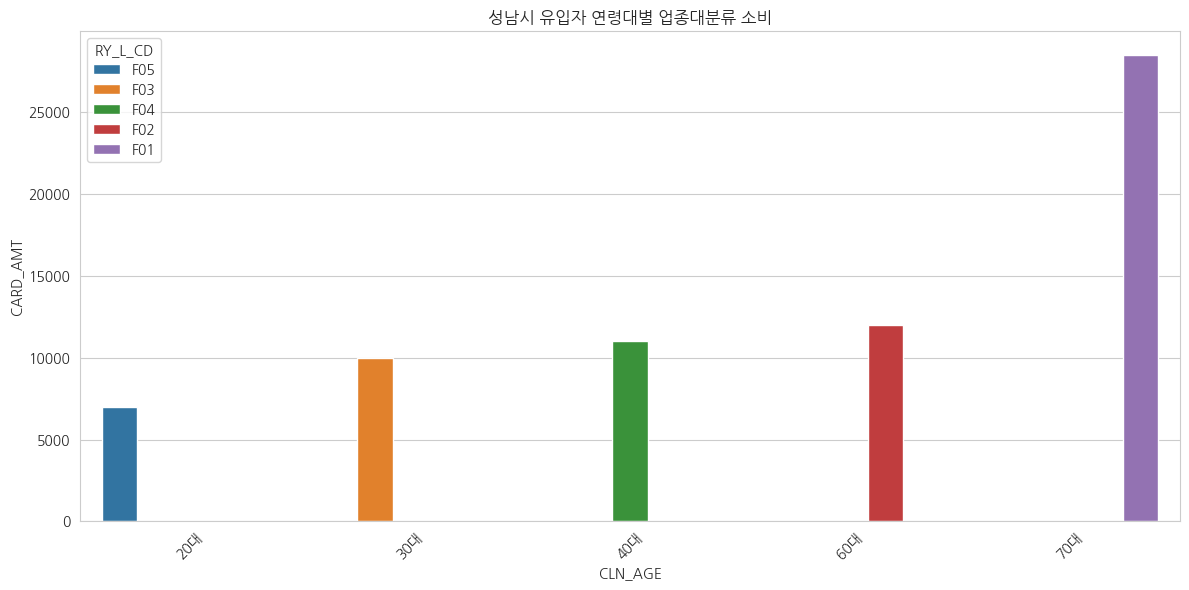

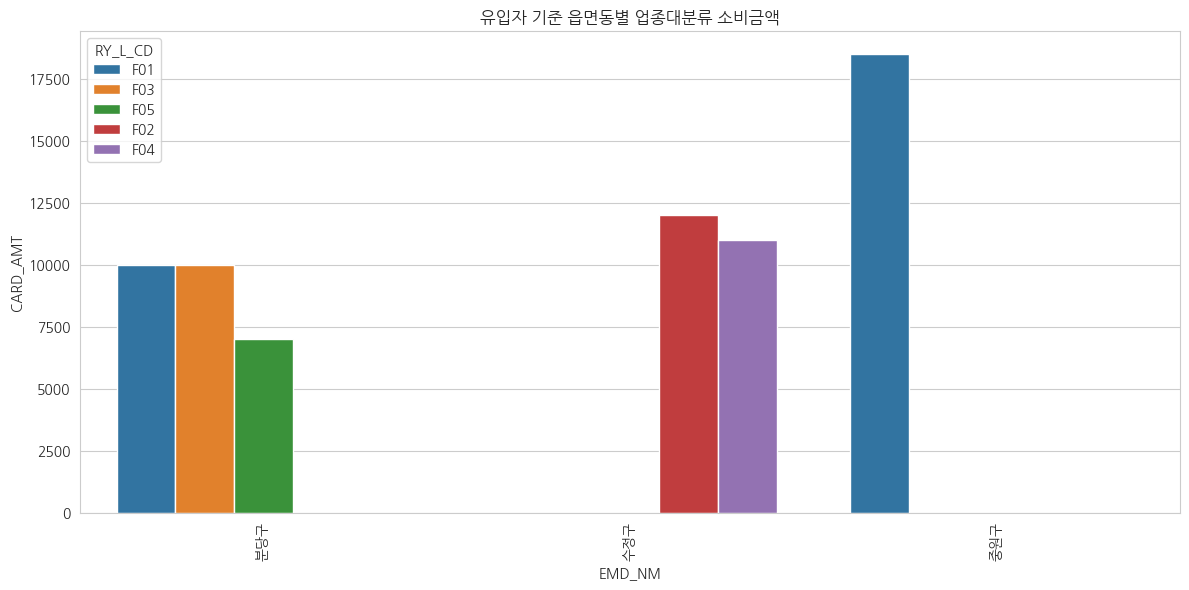

In [ ]:
## 연령대별 업종대분류 시각화 + 고령층과 비교

# 전체 연령대
all_group = df.groupby(['CLN_AGE', 'RY_L_CD'])['CARD_AMT'].sum().reset_index()
plt.figure(figsize=(12,6))
sns.barplot(data=all_group, x='CLN_AGE', y='CARD_AMT', hue='RY_L_CD')
plt.title('연령대별 업종대분류 소비금액')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("연령대별_업종대분류_소비금액.png")

# 고령층 vs 비고령층 비교
df['AGE_LABEL'] = df['IS_SENIOR65'].map({True: '고령층(65+)', False: '기타'})
compare = df.groupby(['AGE_LABEL', 'RY_L_CD'])['CARD_AMT'].sum().reset_index()
plt.figure(figsize=(10,6))
sns.barplot(data=compare, x='RY_L_CD', y='CARD_AMT', hue='AGE_LABEL')
plt.title('고령층 vs 기타 업종대분류 소비금액 비교')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("고령층_비교_업종대분류.png")

## 고령층 업종대분류별 1회 평균 구매금액
senior = df[df['IS_SENIOR65']]
avg = senior.groupby('RY_L_CD')[['CARD_AMT', 'CARD_CNT']].sum()
avg['AVG_PER_PURCHASE'] = avg['CARD_AMT'] / avg['CARD_CNT']
avg = avg.sort_values('AVG_PER_PURCHASE', ascending=False)
avg.to_csv("고령층_1회평균구매금액.csv")

## 유입자가 y면서 연령대별 업종대분류 
inflow = df[df['CLN_REG_YN'] == 'Y']
group = inflow.groupby(['CLN_AGE', 'RY_L_CD'])['CARD_AMT'].sum().reset_index()
plt.figure(figsize=(12,6))
sns.barplot(data=group, x='CLN_AGE', y='CARD_AMT', hue='RY_L_CD')
plt.title('성남시 유입자 연령대별 업종대분류 소비')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("유입자_연령대별_업종대분류.png")


## 유입자(Y) + 읍면동별 업종대분류
group = inflow.groupby(['EMD_NM', 'RY_L_CD'])['CARD_AMT'].sum().reset_index()
plt.figure(figsize=(12,6))
sns.barplot(data=group, x='EMD_NM', y='CARD_AMT', hue='RY_L_CD')
plt.title('유입자 기준 읍면동별 업종대분류 소비금액')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("유입자_읍면동별_업종대분류.png")


완


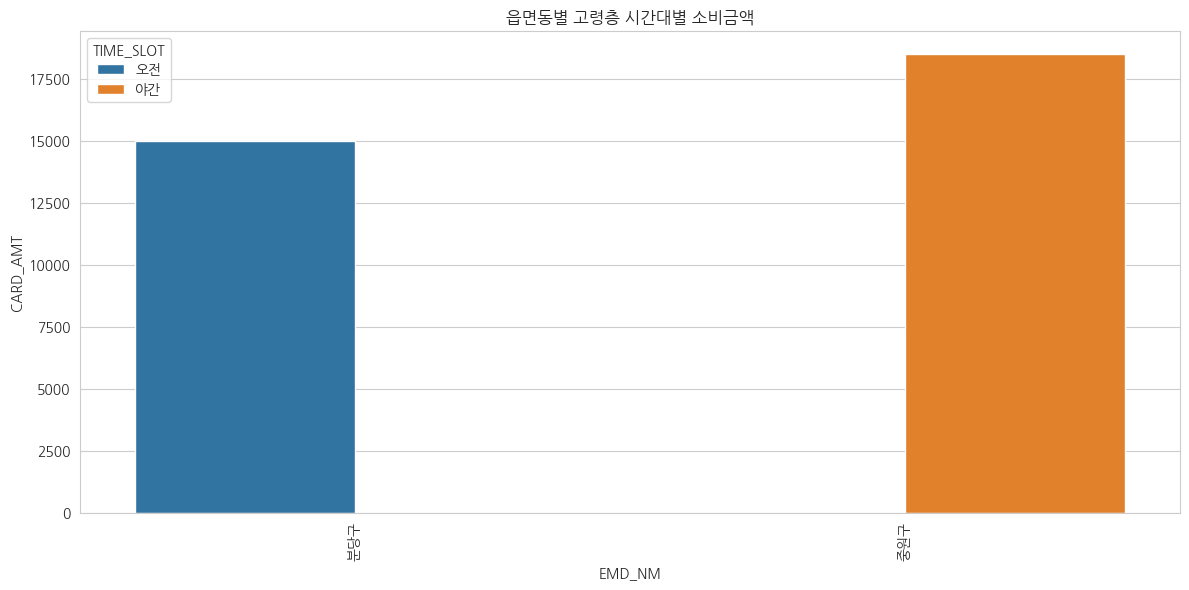

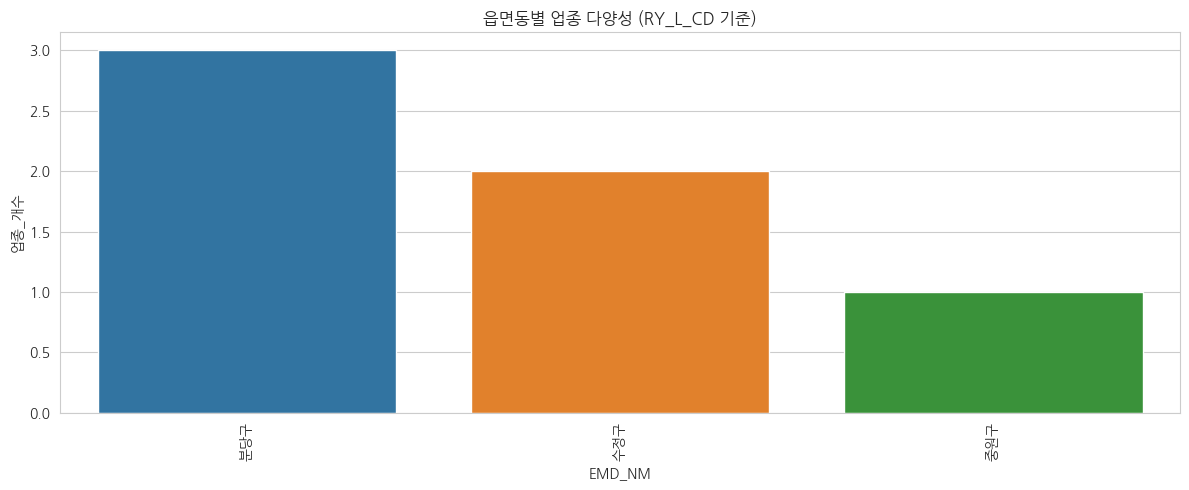

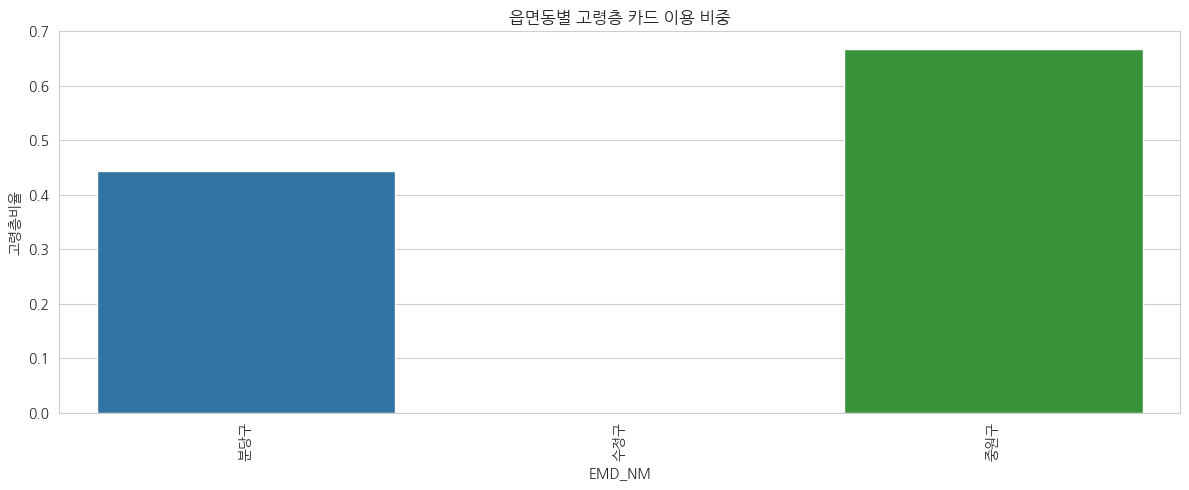

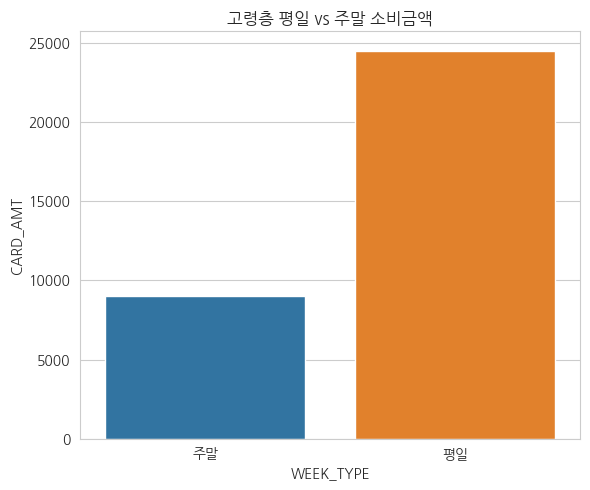

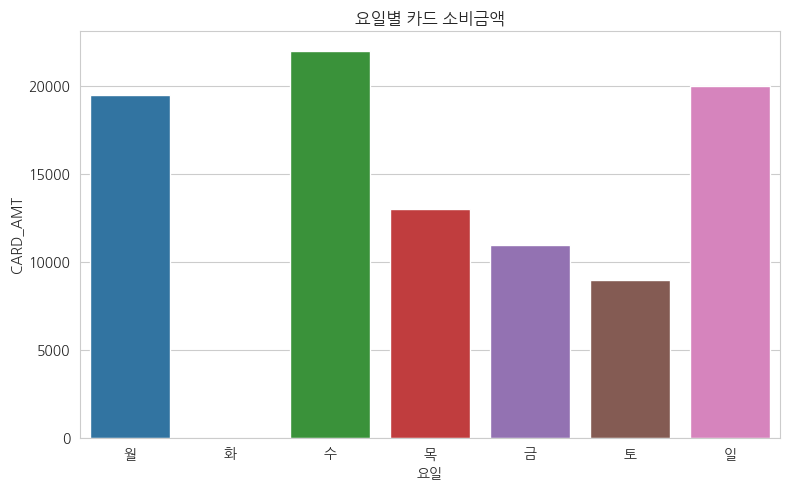

In [ ]:
# 전처리: 성남시만 필터링
df = df[df['SGG_NM'] == '성남시'].copy()
df['CARD_AMT'] = pd.to_numeric(df['CARD_AMT'], errors='coerce')
df['CARD_CNT'] = pd.to_numeric(df['CARD_CNT'], errors='coerce')
df['AGE_NUM'] = df['CLN_AGE'].str.extract(r'(\d+)').astype(float)
df['IS_SENIOR65'] = df['AGE_NUM'] >= 65

# 시간대 구분 함수 (ex. 06~11: 오전 / 12~17: 오후 / 18~23: 야간 / 나머지: 심야)
def time_slot(hour):
    hour = int(hour)
    if 6 <= hour <= 11:
        return '오전'
    elif 12 <= hour <= 17:
        return '오후'
    elif 18 <= hour <= 23:
        return '야간'
    else:
        return '심야'

# 시간대 컬럼 추가
df['TIME_SLOT'] = df['TIME_H'].apply(time_slot)

##읍면동별 시간대별 고령층 소비 밀집도
senior = df[df['IS_SENIOR65']]
senior_time = senior.groupby(['EMD_NM', 'TIME_SLOT'])['CARD_AMT'].sum().reset_index()
plt.figure(figsize=(12,6))
sns.barplot(data=senior_time, x='EMD_NM', y='CARD_AMT', hue='TIME_SLOT')
plt.title('읍면동별 고령층 시간대별 소비금액')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('고령층_읍면동_시간대별소비.png')

## 읍면동별 업종 다양성 (대분류 기준)
industry_diversity = df.groupby('EMD_NM')['RY_L_CD'].nunique().reset_index(name='업종_개수')
plt.figure(figsize=(12,5))
sns.barplot(data=industry_diversity, x='EMD_NM', y='업종_개수')
plt.title('읍면동별 업종 다양성 (RY_L_CD 기준)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('읍면동별_업종_다양성.png')

###  읍면동별 고령층 비중
user_by_age = df.groupby(['EMD_NM', 'IS_SENIOR65'])['CARD_CNT'].sum().reset_index()
total = user_by_age.groupby('EMD_NM')['CARD_CNT'].sum()
senior = user_by_age[user_by_age['IS_SENIOR65'] == True].set_index('EMD_NM')['CARD_CNT']
senior_ratio = (senior / total).fillna(0).reset_index(name='고령층비율')

plt.figure(figsize=(12,5))
sns.barplot(data=senior_ratio, x='EMD_NM', y='고령층비율')
plt.title('읍면동별 고령층 카드 이용 비중')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('읍면동별_고령층_비중.png')


### 요일/주말 분석 추가

df['STD_YMD'] = pd.to_datetime(df['STD_YMD'], errors='coerce')
df['WEEKDAY'] = df['STD_YMD'].dt.dayofweek  # Monday=0

def weekday_label(x):
    if x < 5:
        return '평일'
    else:
        return '주말'

df['WEEK_TYPE'] = df['WEEKDAY'].apply(weekday_label)

# 고령층 주말 vs 평일 소비 비교
group = df[df['IS_SENIOR65']].groupby('WEEK_TYPE')['CARD_AMT'].sum().reset_index()
plt.figure(figsize=(6,5))
sns.barplot(data=group, x='WEEK_TYPE', y='CARD_AMT')
plt.title('고령층 평일 vs 주말 소비금액')
plt.tight_layout()
plt.savefig('고령층_주말_평일_소비비교.png')

# 요일별 소비금액 (전체)
weekday_amt = df.groupby('WEEKDAY')['CARD_AMT'].sum().reset_index()

# 안전하게 요일 매핑
weekday_map = {0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}
weekday_amt['요일'] = weekday_amt['WEEKDAY'].map(weekday_map)

plt.figure(figsize=(8,5))
sns.barplot(data=weekday_amt, x='요일', y='CARD_AMT', order=['월','화','수','목','금','토','일'])
plt.title('요일별 카드 소비금액')
plt.tight_layout()
plt.savefig('요일별_소비금액.png')







print('완')


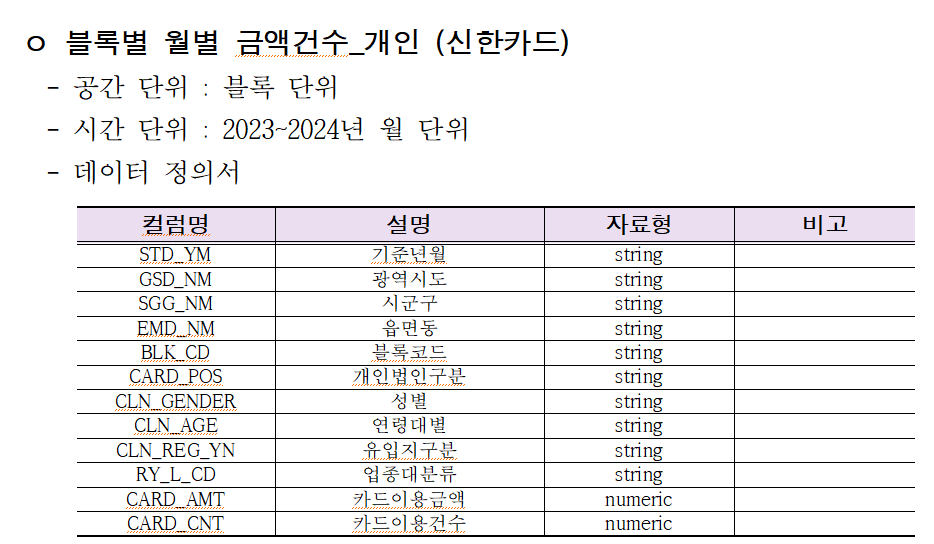

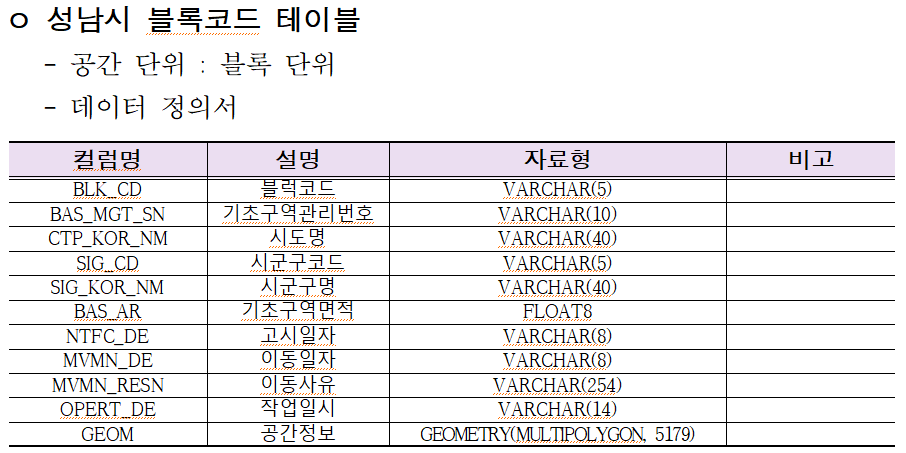

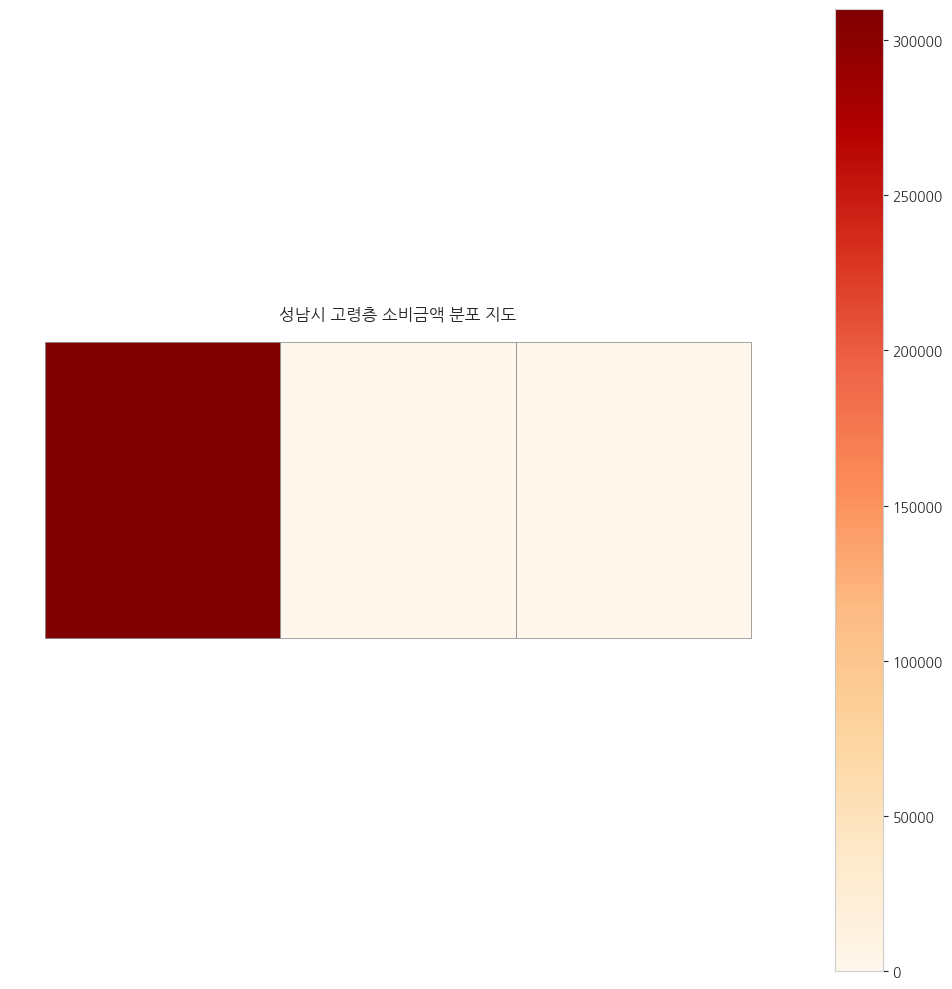

In [ ]:

import geopandas as gpd
# 1. 데이터 불러오기 및 전처리
gdf_blk = gpd.read_file("성남시_블록코드_테이블.shp")
df_consume = pd.read_csv("블록별 월별 금액건수_개인.txt", sep="\t", encoding="utf-8")  ##탭구분자라고 가정  \t
df_consume = df_consume[df_consume['SGG_NM'] == '성남시'].copy()
df_consume['CARD_AMT'] = pd.to_numeric(df_consume['CARD_AMT'], errors='coerce')  # 숫자형으로 변환
df_consume['CARD_CNT'] = pd.to_numeric(df_consume['CARD_CNT'], errors='coerce')
df_consume['AGE_NUM'] = df_consume['CLN_AGE'].str.extract(r'(\d+)').astype(float)   #  숫자만 추출: '70대' → 70 
df_consume['IS_SENIOR65'] = df_consume['AGE_NUM'] >= 65

# 2. 성남시 블록별 소비 TOP5 
blk_sum = df_consume.groupby('BLK_CD')['CARD_AMT'].sum().reset_index().sort_values(by='CARD_AMT', ascending=False)
top5_blk = blk_sum.head(5)['BLK_CD'].tolist()  ## 20개로 봐도 됨.
print("성남시 블록별 소비 TOP5:")
print(blk_sum.head(5))

# 3. 고령층이 자주 이용한 블록 + 업종
senior_blk_ind = df_consume[df_consume['IS_SENIOR65']].groupby(['BLK_CD', 'RY_L_CD'])['CARD_AMT'].sum().reset_index()
senior_blk_ind.to_csv("고령층_블록별_업종소비.csv", index=False)
print("고령층 블록-업종별 소비 상위:")
print(senior_blk_ind.sort_values('CARD_AMT', ascending=False).head(5))

# 5. 블록별 월별 소비 시계열
time_blk = df_consume.groupby(['STD_YM', 'BLK_CD'])['CARD_AMT'].sum().reset_index()
time_blk.to_csv("블록별_월별_소비금액_추이.csv", index=False)
print(" 블록별 월별 소비금액 추이")
print(time_blk.head())

# 6. 고령층 소비 집중도 시각화 블록별
senior_blk = df_consume[df_consume['IS_SENIOR65']].groupby('BLK_CD')['CARD_AMT'].sum().reset_index().rename(columns={'CARD_AMT': '고령층소비금액'})
gdf_merge = gdf_blk.merge(senior_blk, on='BLK_CD', how='left').fillna(0)

fig, ax = plt.subplots(figsize=(10,10))
gdf_merge.plot(column='고령층소비금액', cmap='OrRd', linewidth=0.5, edgecolor='gray', legend=True, ax=ax)
plt.title("성남시 고령층 소비금액 분포 지도")
plt.axis('off')
plt.tight_layout()
plt.savefig("고령층_소비_지도.png")
plt.show()


print("완료")


In [ ]:

# 7. 고령층 정책 타겟 지역 추출 (상위 10%)

threshold = gdf_merge['고령층소비금액'].quantile(0.9)
target_blk = gdf_merge[gdf_merge['고령층소비금액'] >= threshold]
# 한글 컬럼명을 영문으로 변경
target_blk = target_blk.rename(columns={
    '고령층소비금액': 'SENIOR_AMT'
})

# 저장
target_blk.to_file("target_blocks.shp", encoding="utf-8", engine="fiona")

In [ ]:
##  복지시설 위치 (노인복지관 등) -> 복지시설 반경 내 소비 집중도 비교 
## 고령층의 병원 근처 소비 집중 여부 확인